# CRACKING THE HAPPINESS CODE BY NUMBERS 

#### INTRODUCTION 

Can happiness be measured? What external factors may contribute to happiness? 

In [95]:
#importing
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
%matplotlib inline 

In [3]:
# Datasets that are used in the project 
df = pd.read_csv("world-happiness-report-2021.csv")
dr = pd.read_csv("Inequality-adjusted Human Development Index.csv")
dc = pd.read_csv("country_wise_latest.csv")
du = pd.read_csv ("human-freedom-index-2020.csv")

The datapoints I am going to use

In the ("world-happiness-report-2021.csv")[Happiness 2020 Data]
* Country_name = The name of the country                               
* Regional_indicator = The name of the region in which the country is from                         
* Ladder_score =  It is the happiness score, the national average response to the question of life evaluation
* Logged_GDP_per_capita = indicator of total income generated by economic activty in a country; extracted information from World Development Indicators (WDI) 
* Social_support = Average binary reponses to the question "If you were in trouble, do you have relatives or friends you can count on to help you with whatever you need them, or not?"                           
* Healthy_life_expectancy = Data extracted from WHO that indicates the average life span for a person in a country               
* Freedom_to_make_life_choices = national average repsonse to "Are you satisfied or dissatisfied with your freecom to choose whatever you do with your life"               
* Generosity = Determined by pairing with the question "Have you donated money to charity in the past month" on GDP per capita 
* Perceptions_of_corruption = National average responses to two questions: "Is corruption widespread throughout the government or not" and "Is corruption widespread within business or not" 

In the ("Inequality-adjusted Human Development Index.csv") 
* Country = the Country name
* HDI = Human Development Index 
* IHDI = Inequality-adjusted Human Development 
* Loss% = the difference between HDI (Human Development Index) and IHDI (Inequality-adjusted Human Development Index) 

In the ("country_wise_latest.csv") 
* WHO_Region = Regions where Covid-19 took place
* Confirmed = Confirmed case of Covid-19


In the ("human-freedom-index-2020.csv") 
* Region 
* HF_score = Human Freedom score


In [4]:
dc.dtypes

Country/Region             object
Confirmed                   int64
Deaths                      int64
Recovered                   int64
Active                      int64
New cases                   int64
New deaths                  int64
New recovered               int64
Deaths / 100 Cases        float64
Recovered / 100 Cases     float64
Deaths / 100 Recovered    float64
Confirmed last week         int64
1 week change               int64
1 week % increase         float64
WHO_Region                 object
dtype: object

In [122]:
dr.dtypes

Rank            object
Country         object
IHDI           float64
HDI            float64
Loss%          float64
Growth_2010    float64
dtype: object

In [6]:
df.dtypes

Country_name                                  object
Regional_indicator                            object
Ladder_score                                 float64
Standard_error_of_ladder_score               float64
upperwhisker                                 float64
lowerwhisker                                 float64
Logged_GDP_per_capita                        float64
Social_support                               float64
Healthy_life_expectancy                      float64
Freedom_to_make_life_choices                 float64
Generosity                                   float64
Perceptions_of_corruption                    float64
Ladder_score_in_Dystopia                     float64
Explained_by_Log_GDP_per_capita              float64
Explained_by_Social_support                  float64
Explained_by_Healthy_life_expectancy         float64
Explained_by_Freedom_to_make_life_choices    float64
Explained_by_Generosity                      float64
Explained_by_Perceptions_of_corruption       f

In [123]:
du.dtypes

Unnamed: 0                  int64
year                        int64
ISO_code                   object
countries                  object
region                     object
                           ...   
ef_regulation_business    float64
ef_regulation             float64
ef_score                  float64
ef_rank                   float64
womens_freedom            float64
Length: 113, dtype: object

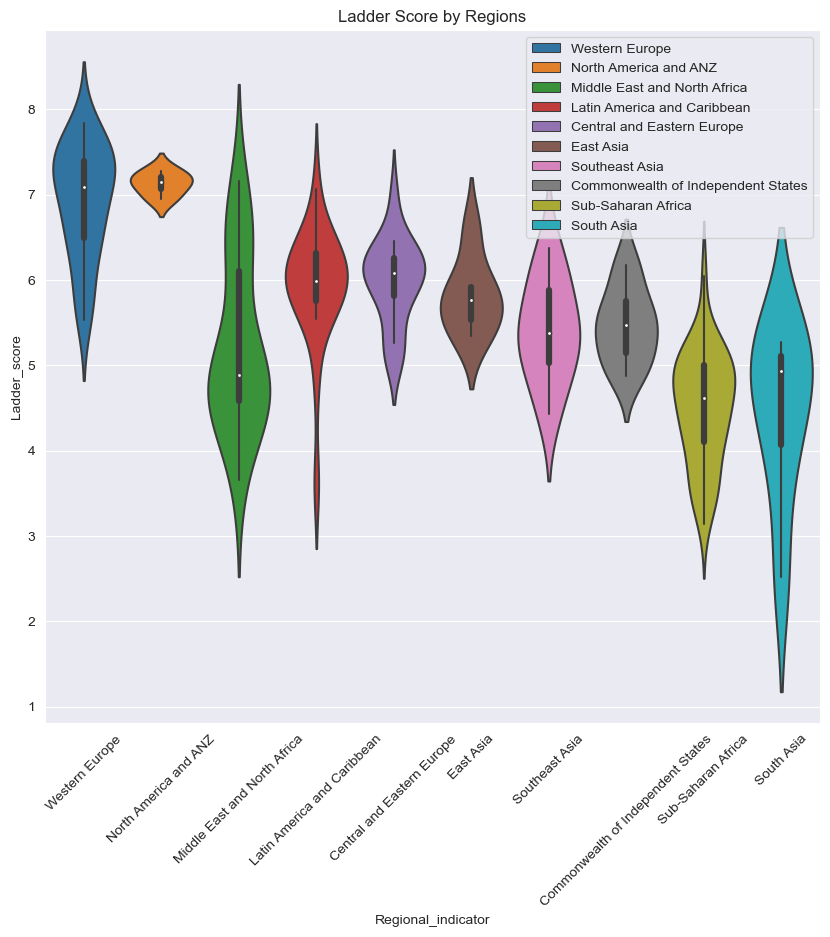

In [7]:
#Does ladder score between countries in the same region varies?
plt.figure(figsize= (10,9))
sns.set_style('darkgrid')
sns.violinplot(x="Regional_indicator",y="Ladder_score",data=df, hue="Regional_indicator", dodge = False).set_title("Ladder Score by Regions")
plt.xticks(rotation=45)
plt.legend(loc=0)

### ECONOMICS

Text(0.5, 1.0, 'Logged GDP per Capita vs Ladder Score')

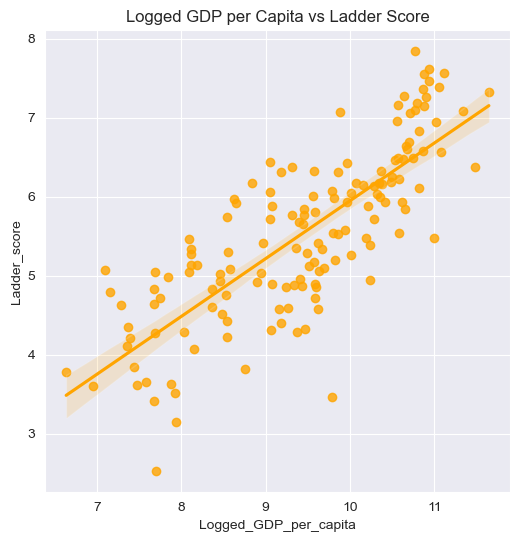

In [47]:
#What is ladder score's relation to GDP per Capita?
plt.figure(figsize= (6,6))
sns.regplot(x="Logged_GDP_per_capita", y= "Ladder_score",  data = df, color = "Orange").set_title ("Logged GDP per Capita vs Ladder Score")

Text(0.5, 1.0, 'HDI vs IHDI')

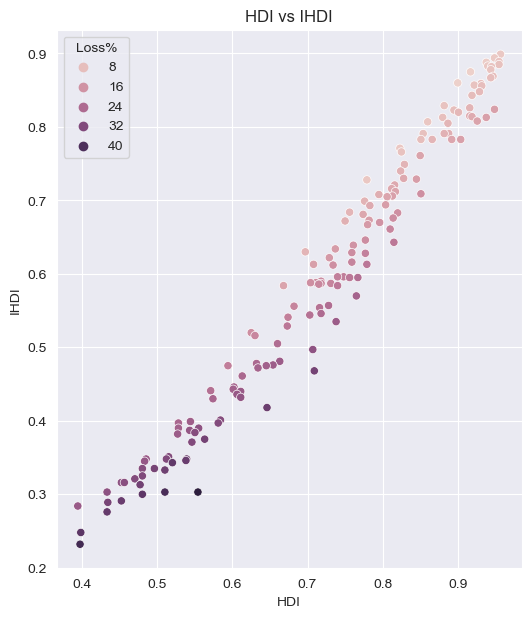

In [49]:
#Are there datas that are not included in the GDP? 
#The Human Development Index is a statistic composite index of life expectancy, education, and per capita income indicators
#It helps us understanding the growth of human development in terms of achievement 
plt.figure(figsize= (6,7))
sns.scatterplot(x="HDI", y= "IHDI", data = dr, hue = "Loss%").set_title("HDI vs IHDI")

### CORRUPTION

Text(0.5, 1.0, 'Perception of Corruption and Ladder Score')

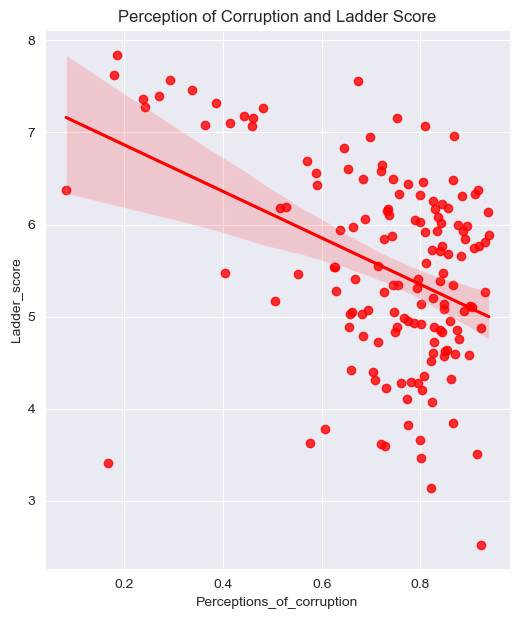

In [50]:
#How does perception of corruption relate to happiness?
plt.figure(figsize= (6,7))
sns.regplot(x="Perceptions_of_corruption", y= "Ladder_score",  data = df, color = "red").set_title ("Perception of Corruption and Ladder Score")

Text(0.5, 1.0, 'Perceptions of Corruption vs Freedom to Make Life Choices')

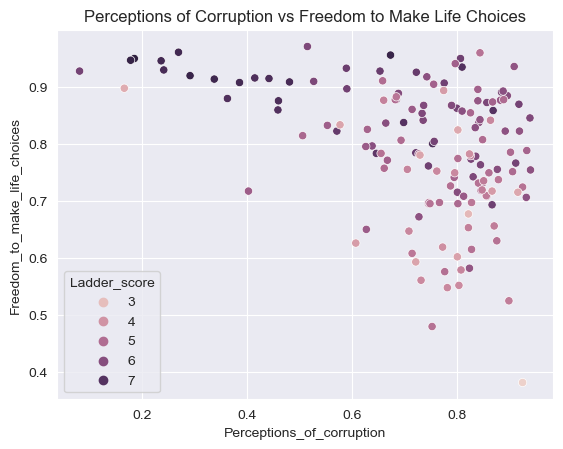

In [133]:
sns.scatterplot(x="Perceptions_of_corruption", y = "Freedom_to_make_life_choices", hue= "Ladder_score", data = df).set_title("Perceptions of Corruption vs Freedom to Make Life Choices")

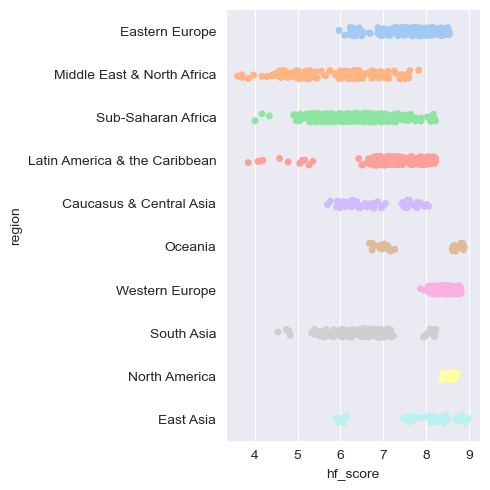

In [136]:
sns.catplot( data=du, y="region", x="hf_score", palette="pastel", edgecolor=".6",)

### SUPPORT

Text(0.5, 1.0, 'Social Support vs Ladder Score')

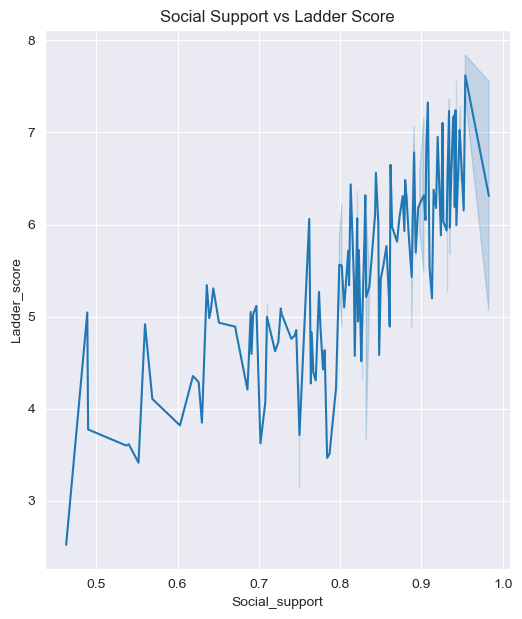

In [57]:
#How does social support relate to happiness 
plt.figure(figsize= (6,7))
sns.lineplot(x="Social_support", y= "Ladder_score",  data = df).set_title("Social Support vs Ladder Score")

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Greece'),
  Text(1, 0, 'Japan'),
  Text(2, 0, 'Botswana'),
  Text(3, 0, 'Portugal'),
  Text(4, 0, 'Georgia'),
  Text(5, 0, 'Morocco'),
  Text(6, 0, 'Azerbaijan'),
  Text(7, 0, 'Romania'),
  Text(8, 0, 'Czech Republic'),
  Text(9, 0, 'Lithuania')])

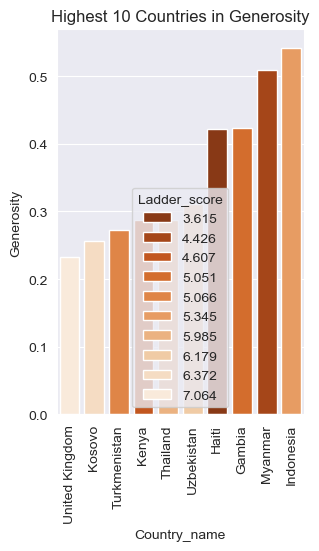

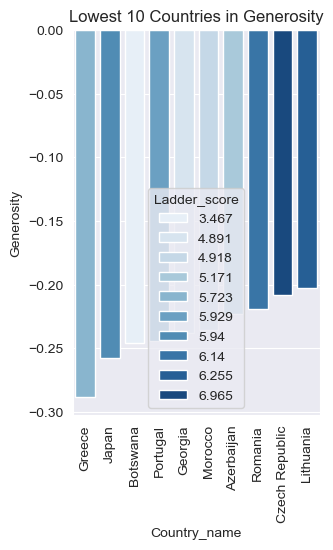

In [11]:
#How does happiness be affected by one's health?
plt.figure(figsize= (7,5))
plt.subplot (1,2,1)
sns.barplot(x="Country_name", y="Generosity", data = df.sort_values("Generosity").tail(10), hue = "Ladder_score", palette = "Oranges_r", dodge=False).set_title("Highest 10 Countries in Generosity")
plt.xticks(rotation=90)
plt.figure(figsize= (7,5))
plt.subplot (1,2,2)
sns.barplot(x="Country_name", y="Generosity", data = df.sort_values("Generosity").head(10), hue = "Ladder_score", palette = "Blues", dodge=False).set_title("Lowest 10 Countries in Generosity")
plt.xticks(rotation=90)

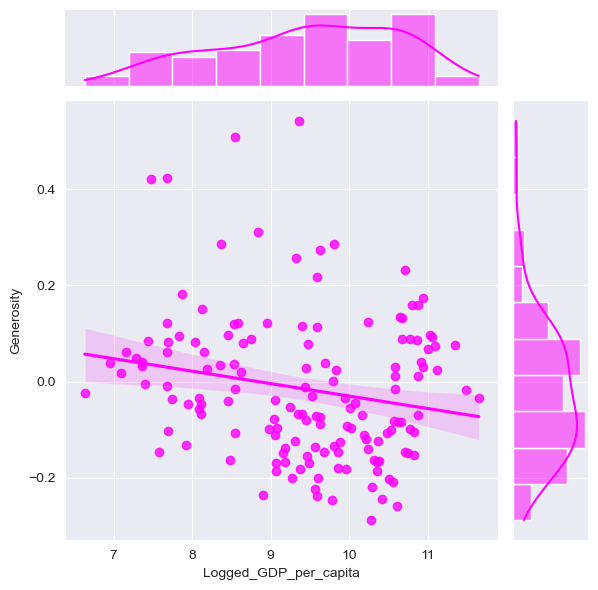

In [27]:
#Since generosity depends on GDP, what is their relationship?
sns.jointplot(data = df, x = "Logged_GDP_per_capita", y = "Generosity", kind = "reg", color = "Magenta")

### HEALTH

[Text(0.5, 1.0, 'Ladder score and Life Expectancy')]

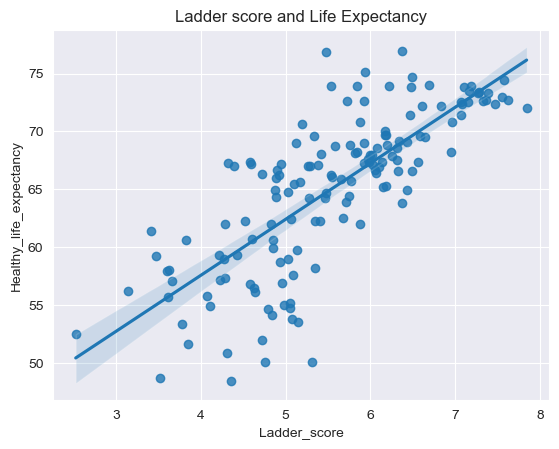

In [127]:
#How does life expectancy relate to ladder score I
sns.regplot (x="Ladder_score", y="Healthy_life_expectancy", data=df).set(title="Ladder score and Life Expectancy")

(array([0, 1, 2, 3, 4, 5]),
 [Text(0, 0, 'Eastern Mediterranean'),
  Text(1, 0, 'Europe'),
  Text(2, 0, 'Africa'),
  Text(3, 0, 'Americas'),
  Text(4, 0, 'Western Pacific'),
  Text(5, 0, 'South-East Asia')])

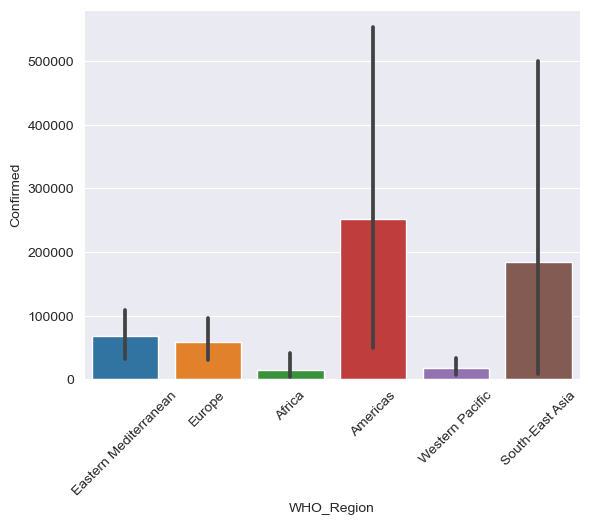

In [132]:
sns.barplot(data=dc, x="WHO_Region", y="Confirmed").set_title("Region and Confirmed Cases")
plt.xticks(rotation=45)

### CONCLUSION 